In [ ]:
import kagglehub
import shutil
import os

# Download latest version
path = kagglehub.dataset_download("yufengsui/mobile-games-ab-testing")

print("Path to dataset files:", path)

100%|██████████| 490k/490k [00:00<00:00, 43.5MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/yufengsui/mobile-games-ab-testing/versions/1


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportions_ztest
from scipy import stats

In [ ]:
df = pd.read_csv("/root/.cache/kagglehub/datasets/yufengsui/mobile-games-ab-testing/versions/1/cookie_cats.csv")

In [ ]:
df

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True
...,...,...,...,...,...
90184,9999441,gate_40,97,True,False
90185,9999479,gate_40,30,False,False
90186,9999710,gate_30,28,True,False
90187,9999768,gate_40,51,True,False


In [ ]:
df.userid.nunique()

90189

In [ ]:
df.version.value_counts()

,count
version,
gate_40,45489
gate_30,44700


In [ ]:
df.sum_gamerounds.describe()

,sum_gamerounds
count,90189.000000
mean,51.872457
std,195.050858
min,0.000000
25%,5.000000
50%,16.000000
75%,51.000000
max,49854.000000


In [ ]:
df.retention_1.value_counts()

,count
retention_1,
False,50036
True,40153


In [ ]:
df.retention_1.sum()

np.int64(40153)

In [ ]:
df.retention_7.value_counts()

,count
retention_7,
False,73408
True,16781


In [ ]:
df.groupby("version")[['sum_gamerounds', 'retention_1', 'retention_7']].mean()

,sum_gamerounds,retention_1,retention_7
version,,,
gate_30,52.456264,0.448188,0.190201
gate_40,51.298776,0.442283,0.182000


In [ ]:
df_95 = df[df['sum_gamerounds'] <= df['sum_gamerounds'].quantile(0.95)]

<Axes: xlabel='sum_gamerounds', ylabel='Count'>

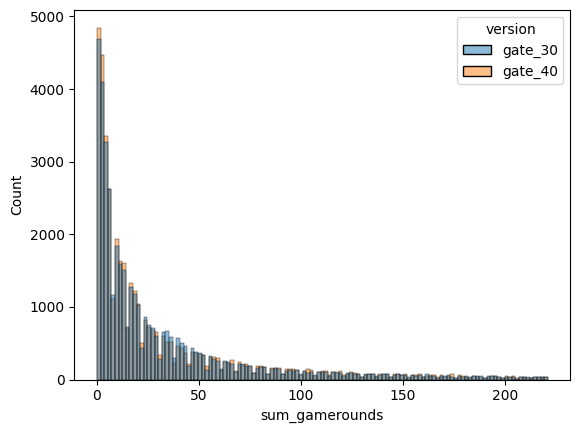

In [ ]:
sns.histplot(data=df_95, x="sum_gamerounds", hue='version')

In [ ]:
stat, pval = stats.ttest_ind(df[df['version']=='gate_30'].sum_gamerounds, df[df['version']=='gate_40'].sum_gamerounds, equal_var=False, alternative="greater")
print(pval)

0.18796219204663112


In [ ]:
count = np.array([df[df['version']=='gate_30'].retention_1.sum(), df[df['version']=='gate_40'].retention_1.sum()])
nobs = np.array([df[df['version']=='gate_30'].shape[0], df[df['version']=='gate_40'].shape[0]])
stat, pval = proportions_ztest(count, nobs, alternative='larger')
print(pval)

0.03720482764845957


In [ ]:
count = np.array([df[df['version']=='gate_30'].retention_7.sum(), df[df['version']=='gate_40'].retention_7.sum()])
nobs = np.array([df[df['version']=='gate_30'].shape[0], df[df['version']=='gate_40'].shape[0]])
stat, pval = proportions_ztest(count, nobs, alternative='larger')
print(pval)

0.0007771249878071645


In [ ]:
df.groupby("version")["sum_gamerounds"].quantile([0.25, 0.5, 0.75, 0.95, 0.97, 0.98, 0.99, 0.999, 0.99999]).unstack()


,0.25000,0.50000,0.75000,0.95000,0.97000,0.98000,0.99000,0.99900,0.99999
version,,,,,,,,,
gate_30,5.0,17.0,50.0,222.0,301.03,367.02,493.00,1052.612,28893.29793
gate_40,5.0,16.0,52.0,220.0,296.36,361.00,492.12,1086.096,2482.61152


In [ ]:
df[['version', 'sum_gamerounds']].sort_values(by='sum_gamerounds', ascending=False)

,version,sum_gamerounds
57702,gate_30,49854
7912,gate_30,2961
29417,gate_40,2640
43671,gate_30,2438
48188,gate_40,2294
...,...,...
86102,gate_40,0
86092,gate_40,0
3050,gate_30,0
86120,gate_30,0


In [ ]:
df = df[df['sum_gamerounds'] < 3000]

In [ ]:
from statsmodels.stats.proportion import confint_proportions_2indep

count = np.array([df[df['version']=='gate_30'].retention_1.sum(), df[df['version']=='gate_40'].retention_1.sum()])
nobs = np.array([df[df['version']=='gate_30'].shape[0], df[df['version']=='gate_40'].shape[0]])

stat, pval = proportions_ztest(count, nobs)
ci_low, ci_high = confint_proportions_2indep(count[0], nobs[0], count[1], nobs[1], method='wald')

print(pval)

0.0739207603418346


In [ ]:
from statsmodels.stats.proportion import confint_proportions_2indep

count = np.array([df[df['version']=='gate_30'].retention_1.sum(), df[df['version']=='gate_40'].retention_1.sum()])
nobs = np.array([df[df['version']=='gate_30'].shape[0], df[df['version']=='gate_40'].shape[0]])

stat, pval = proportions_ztest(count, nobs)
ci_low, ci_high = confint_proportions_2indep(count[0], nobs[0], count[1], nobs[1], method='wald')

print(f"p-value: {pval:.4f}")
print(f"95% ДИ разницы долей (gate_30 - gate_40): [{ci_low:.5f}, {ci_high:.5f}]")


p-value: 0.0739
95% ДИ разницы долей (gate_30 - gate_40): [-0.00057, 0.01240]


In [ ]:
count = np.array([df[df['version']=='gate_30'].retention_7.sum(), df[df['version']=='gate_40'].retention_7.sum()])
nobs = np.array([df[df['version']=='gate_30'].shape[0], df[df['version']=='gate_40'].shape[0]])
stat, pval = proportions_ztest(count, nobs)
print(pval)

0.0015917731773993442


In [ ]:
df.groupby("version")["sum_gamerounds"].quantile([0.25, 0.5, 0.75, 0.95, 0.97, 0.98, 0.99, 0.999, 0.99999]).unstack()

,0.25000,0.50000,0.75000,0.95000,0.97000,0.98000,0.99000,0.99900,0.99999
version,,,,,,,,,
gate_30,5.0,17.0,50.0,222.0,301.00,367.0,493.00,1045.510,2727.22946
gate_40,5.0,16.0,52.0,220.0,296.36,361.0,492.12,1086.096,2482.61152


In [ ]:
stat, pval = stats.ttest_ind(df[df['version']=='gate_30'].sum_gamerounds, df[df['version']=='gate_40'].sum_gamerounds, equal_var=False)
print(pval)

0.9494686215464458


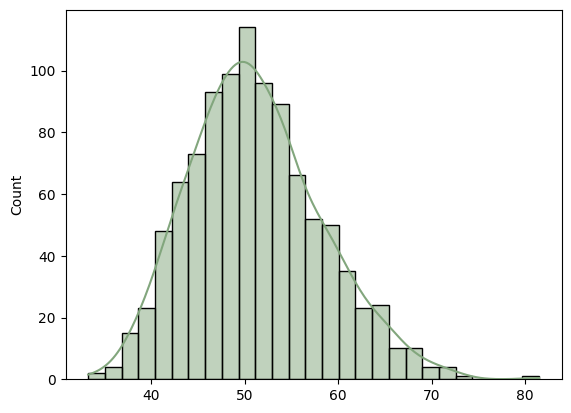

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

population = df[df['version'] == 'gate_30']['sum_gamerounds'].values
means = [np.random.choice(population, size=200, replace=False).mean() for _ in range(1000)]

sns.histplot(means, kde=True, color='#82A67D')
plt.show()
